## Setup

In [2]:
%env TALLTABLE_DB_DIR=/mnt/sdceph/users/spherex/talltable

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

from astropy.io import fits
from astropy.coordinates import SkyCoord
from astropy.cosmology import Planck18
from astropy import units as u
from astropy import constants as const
from astroquery.ipac.irsa import Irsa
from pprint import pprint

import healpy
from tqdm.auto import tqdm

from talltable import PixelQuery

env: TALLTABLE_DB_DIR=/mnt/sdceph/users/spherex/talltable


## Configuration

In [3]:
Z_MIN, Z_MAX = 0.5, 0.51

N_GALAXIES = 500  # number to draw from the z-restricted sample; None = use all of them

QUERY_RADIUS_ARCMIN = 3.0  # ~1 Mpc (comoving) at z=0.5

WL_REST_HALPHA = 0.656  # microns, rest-frame H-alpha
RESOLUTION = 80         # R = lambda / dlambda
N_WL_BINS = 15

## Load LRG sample and pick a narrow redshift band

In [4]:
with fits.open('../data/LRG_NGC_clustering.dat.fits') as hdul:
    data = hdul[1].data
    pprint(hdul[1].header)

XTENSION= 'BINTABLE'           / binary table extension                         
BITPIX  =                    8 / array data type                                
NAXIS   =                    2 / number of array dimensions                     
NAXIS1  =                   97 / length of dimension 1                          
NAXIS2  =              1476135 / length of dimension 2                          
PCOUNT  =                    0 / number of group parameters                     
GCOUNT  =                    1 / number of groups                               
TFIELDS =                   13 / number of table fields                         
TTYPE1  = 'TARGETID'                                                            
TFORM1  = 'K       '                                                            
TTYPE2  = 'Z       '                                                            
TFORM2  = 'D       '                                                            
TTYPE3  = 'NTILE   '        

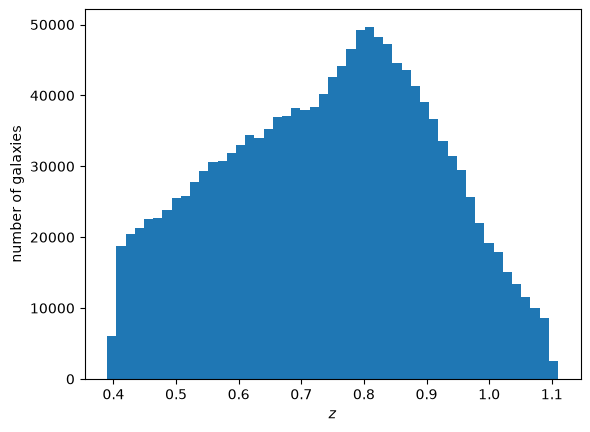

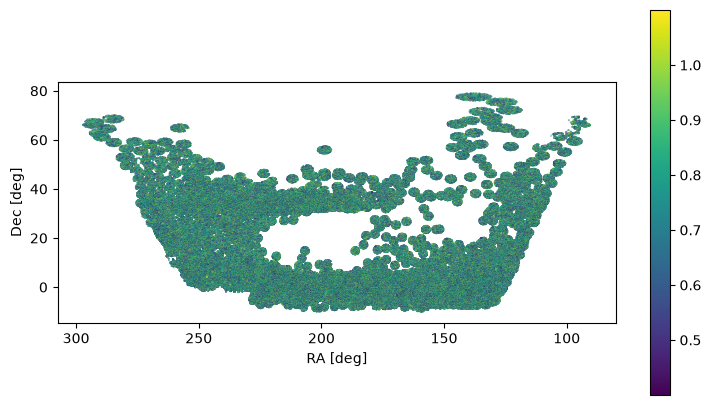

In [5]:
plt.hist(data['Z'], bins=np.linspace(0.39, 1.11, 50))
plt.xlabel('$z$')
plt.ylabel('number of galaxies')
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
_s = ax.scatter(data['RA'], data['DEC'], c=data['Z'], marker='.', s=0.1)
ax.axis('scaled')
ax.xaxis.set_inverted(True)
ax.set_xlabel('RA [deg]')
ax.set_ylabel('Dec [deg]')
fig.colorbar(_s)
plt.show()

In [6]:
mask = (data['Z'] > Z_MIN) & (data['Z'] < Z_MAX)
print(np.count_nonzero(mask))

sample = data[mask]

17706


## Sort by HEALPix index and pick a subsample of galaxies

(Sorting by HEALPix index means a contiguous slice of the sorted array is a spatially clustered group of galaxies -- convenient for pulling a manageable subsample without querying the whole footprint.)

In [7]:
hp15 = healpy.ang2pix(2**15, sample['RA'], sample['DEC'], nest=True, lonlat=True)
sort_idx = np.argsort(hp15)

sample = sample[sort_idx]
hp15 = hp15[sort_idx]

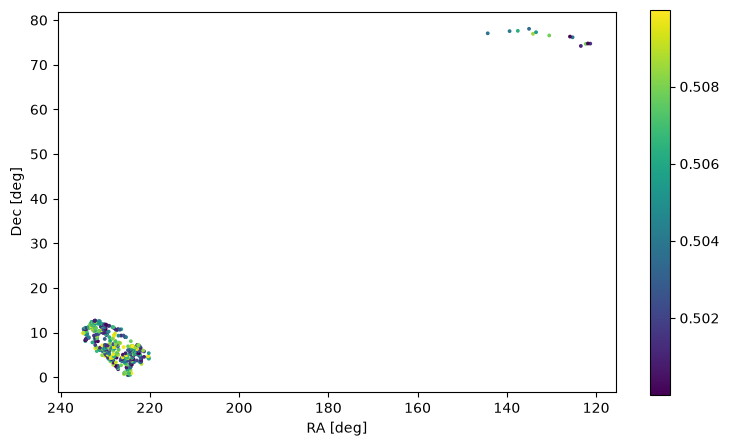

In [8]:
rng = np.random.default_rng(112)

if N_GALAXIES is None or N_GALAXIES >= len(hp15):
    tiny_sample = sample
else:
    chosen = rng.choice(len(hp15), size=1).item()
    lo = max(0, chosen - N_GALAXIES // 2)
    hi = min(len(hp15), lo + N_GALAXIES)
    lo = hi - N_GALAXIES

    tiny_mask = np.zeros_like(hp15, dtype=bool)
    tiny_mask[lo:hi] = True
    tiny_sample = sample[tiny_mask]

fig, ax = plt.subplots(figsize=(9, 5))
_s = ax.scatter(tiny_sample['RA'], tiny_sample['DEC'], c=tiny_sample['Z'], marker='o', s=3)
ax.axis('scaled')
ax.xaxis.set_inverted(True)
ax.set_xlabel('RA [deg]')
ax.set_ylabel('Dec [deg]')
fig.colorbar(_s)
plt.show()

## Bin edges

`r_bins` fixed up front from the highest-z galaxy in the sample at the fixed query radius (no second pass over the data needed). `wl_bins` is a narrow rest-frame band around H-alpha (656nm), log-spaced at spectral resolution R = lambda/dlambda (see Configuration cell). `QUERY_WL_MIN`/`QUERY_WL_MAX` is the fixed observed-frame band -- widened using `Z_MIN`/`Z_MAX` so it covers every galaxy's redshifted H-alpha window regardless of its individual z within the sample.

In [9]:
z_min, z_max = tiny_sample['Z'].min(), tiny_sample['Z'].max()

r_max = (QUERY_RADIUS_ARCMIN * u.arcmin).to(u.rad).value \
        * Planck18.comoving_transverse_distance(z_max).to(u.Mpc).value
r_bins = np.linspace(0, 1.05 * r_max, 15)   # 5% pad for the disc query's inclusive edge

# narrow rest-frame band around H-alpha, log-spaced at resolution R = lambda/dlambda
half_ln_width = (N_WL_BINS / RESOLUTION) / 2
WL_REST_MIN = WL_REST_HALPHA * np.exp(-half_ln_width)
WL_REST_MAX = WL_REST_HALPHA * np.exp(+half_ln_width)
wl_bins = np.geomspace(WL_REST_MIN, WL_REST_MAX, N_WL_BINS + 1)

# fixed observed-frame query band wide enough to cover every galaxy's redshifted H-alpha window
QUERY_WL_MIN = WL_REST_MIN * (1 + Z_MIN)
QUERY_WL_MAX = WL_REST_MAX * (1 + Z_MAX)

n_r, n_wl = len(r_bins) - 1, len(wl_bins) - 1

## Query + stack

Streams one galaxy at a time (query -> bin -> accumulate -> discard) rather than holding every galaxy's pixel table in memory at once.

`.wavelength(QUERY_WL_MIN, QUERY_WL_MAX)` restricts every query to the fixed observed-frame band that could redshift into our H-alpha rest-frame window, cutting the amount of data pulled per query.

`flags(mask_known_source=True)` excludes pixels near known (SPHEREx Reference Catalog) sources -- our own LRGs are compact/unresolved at SPHEREx's PSF scale and so are themselves flagged at r=0, and including them was producing a spurious dip at small r before this was added. Note this also means the innermost bin(s) are underrepresented relative to what a fully unmasked map would give -- worth revisiting (e.g. splitting into a masked-inner / unmasked-outer query) if the innermost bins turn out to matter a lot.

Also tracks `sum_I2` (sum of squares) alongside `sum_I`/`count`, so we can get the per-bin variance -- useful for spotting bins whose scatter across exposures is much larger than the continuum's (e.g. the ~1.1um observed-frame line, likely geocoronal He I -- narrowing to 15 wavelength bins pulled our query band below it, but worth keeping an eye on).

In [9]:
sum_I  = np.zeros((n_r, n_wl))
sum_I2 = np.zeros((n_r, n_wl))
count  = np.zeros((n_r, n_wl), dtype=np.int64)

for row in tqdm(tiny_sample):
    z = row['Z']
    query = (
        PixelQuery(web=False)
        .disc(row['RA'], row['DEC'], QUERY_RADIUS_ARCMIN)
        .with_wavelengths()
        .flags(mask_known_source=False)
        .wavelength(QUERY_WL_MIN, QUERY_WL_MAX)
    )
    _table = query.execute()

    gal_coord = SkyCoord(ra=row['RA'], dec=row['DEC'], unit='deg')
    ra, dec = healpy.pix2ang(2**22, _table.column("hphigh").to_numpy(), nest=True, lonlat=True)
    pixel_coords = SkyCoord(ra=ra, dec=dec, unit='deg')

    dist = gal_coord.separation(pixel_coords).to(u.rad).value \
           * Planck18.comoving_transverse_distance(z)
    r_rest = dist.to(u.Mpc).value

    wavelen_obs   = _table.column("wavelength").to_numpy()
    freq_obs      = (const.c / (wavelen_obs * u.micrometer)).to(u.Hz).value
    intensity_obs = freq_obs * (_table.column("flux").to_numpy() - _table.column("zodi").to_numpy())

    wl_rest = wavelen_obs / (1 + z)
    I_rest  = (1 + z)**4 * intensity_obs

    i_r  = np.digitize(r_rest,  r_bins)  - 1
    i_wl = np.digitize(wl_rest, wl_bins) - 1
    valid = (i_r >= 0) & (i_r < n_r) & (i_wl >= 0) & (i_wl < n_wl)

    np.add.at(sum_I,  (i_r[valid], i_wl[valid]), I_rest[valid])
    np.add.at(sum_I2, (i_r[valid], i_wl[valid]), I_rest[valid] ** 2)
    np.add.at(count,  (i_r[valid], i_wl[valid]), 1)

# mean intensity per (r, wavelength) bin == WW/DD of the marked-correlation-function estimator,
# with "mark" = pixel intensity and pair count = `count`
stack = np.where(count > 0, sum_I / count, np.nan)
r_c  = 0.5 * (r_bins[:-1] + r_bins[1:])
wl_c = 0.5 * (wl_bins[:-1] + wl_bins[1:])

  0%|          | 0/500 [00:00<?, ?it/s]

## Background subtraction

Estimated per wavelength bin from the *pooled* outer annulus across all galaxies (not per-galaxy -- a single galaxy's own outer annulus is too few pixels per wavelength bin to give a stable estimate, which was causing spurious negative dips).

In [10]:
outer = r_c > 0.8 * r_c.max()
background = np.nanmean(stack[outer, :], axis=0)
stack_bgsub = stack - background[None, :]

In [11]:
variance  = np.where(count > 1, sum_I2 / count - (sum_I / count) ** 2, np.nan)
stack_err = np.sqrt(variance / count)   # SEM = sample std / sqrt(N), not stack/sqrt(count)

## Plots

Raw (no background subtraction) first, to keep an eye on instrumental features like the ~1.1um (observed) line before it gets folded into the background estimate.

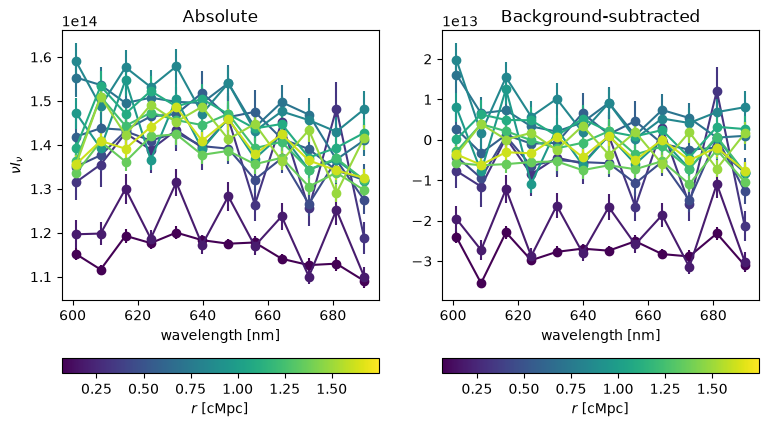

In [12]:
fig, axs = plt.subplots(1, 2, figsize=(9, 5))
cmap = plt.get_cmap('viridis')
norm = mpl.colors.Normalize(r_c.min(), r_c.max())
for i in range(0, n_r - 1):
    axs[0].errorbar(wl_c[:-3] * 1e3, stack[i, :-3], yerr=stack_err[i, :-3],
                     marker='o', color=cmap(norm(r_c[i])))
axs[0].set_xlabel('wavelength [nm]')
axs[0].set_ylabel(r'$\nu I_\nu$')
axs[0].set_title('Absolute')
fig.colorbar(mpl.cm.ScalarMappable(norm, cmap), ax=axs[0], label=r'$r$ [cMpc]', location='bottom')

for i in range(0, n_r - 1):
    axs[1].errorbar(wl_c[:-3] * 1e3, stack_bgsub[i, :-3], yerr=stack_err[i, :-3],
                     marker='o', color=cmap(norm(r_c[i])))
axs[1].set_xlabel('wavelength [nm]')
# axs[1].set_ylabel(r'$\nu I_\nu$')
axs[1].set_title('Background-subtracted')
fig.colorbar(mpl.cm.ScalarMappable(norm, cmap), ax=axs[1], label=r'$r$ [cMpc]', location='bottom')

plt.show()

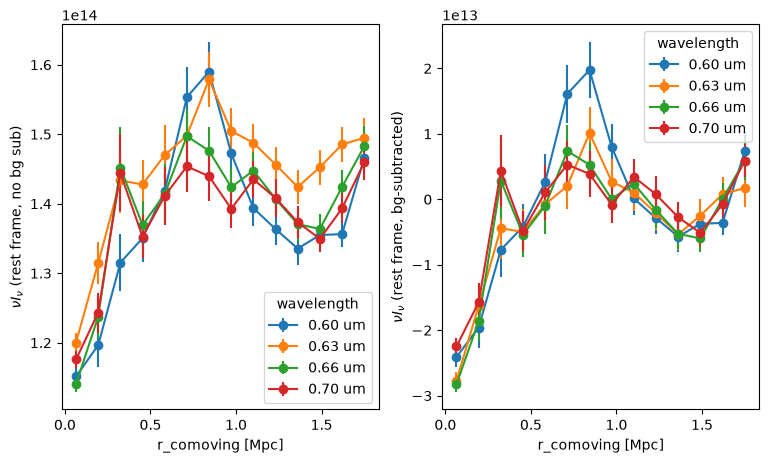

In [13]:
fig, axs = plt.subplots(1, 2, figsize=(9, 5))
for j in range(0, n_wl - 1, 4):
    axs[0].errorbar(r_c, stack[:, j], yerr=stack_err[:, j], marker='o', label=f'{wl_c[j]:.2f} um')
axs[0].set_xlabel('r_comoving [Mpc]')
axs[0].set_ylabel(r'$\nu I_\nu$ (rest frame, no bg sub)')
axs[0].legend(title='wavelength')

for j in range(0, n_wl - 1, 4):
    axs[1].errorbar(r_c, stack_bgsub[:, j], yerr=stack_err[:, j], marker='o', label=f'{wl_c[j]:.2f} um')
axs[1].set_xlabel('r_comoving [Mpc]')
axs[1].set_ylabel(r'$\nu I_\nu$ (rest frame, bg-subtracted)')
axs[1].legend(title='wavelength')
plt.show()

## Diagnostics

Per-bin variance, to check whether the ~1.1um (observed) feature is a real but highly time-variable line (e.g. geocoronal He I, which varies a lot with orbital phase/limb angle) rather than something spatially localized -- a wavelength bin with much higher variance than its neighbors, despite similar pair counts, points to exposure-to-exposure variability rather than a spatial gradient.

### Single-galaxy raw spectrum check

Is the ~630/635nm (rest) peak really offset from the predicted H-alpha location, or is that a stacking artifact? Pick one galaxy at random (no brightness column to select on, so just re-roll `GAL_SEED` if the single-object S/N is too poor to say anything), query a small 30 arcsec disc directly around it (small enough that every pixel should be galaxy-associated, no `r` cut needed), and scatter-plot its raw (observed wavelength, $\nu I_\nu$) pixel pairs -- no wavelength binning -- against the observed-frame wavelength predicted for H-alpha at that galaxy's own catalog redshift. If the excess in this single object also sits away from the predicted line, the offset isn't something introduced by our stacking/binning -- it's upstream (DESI `Z`, SPHEREx wavelength calibration, or a misidentified line).

TARGETID 39628035095270441, z=0.5070, 241 pixels within 0.25 arcmin


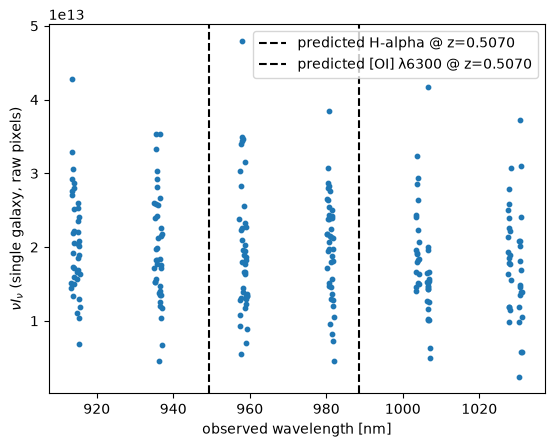

TARGETID 39627945282635481, z=0.5042, 241 pixels within 0.25 arcmin


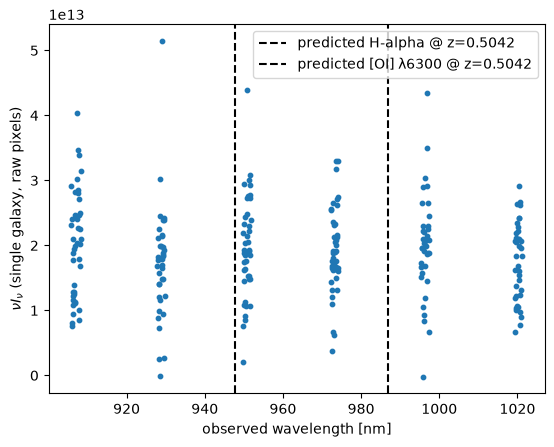

TARGETID 39628046910623179, z=0.5028, 259 pixels within 0.25 arcmin


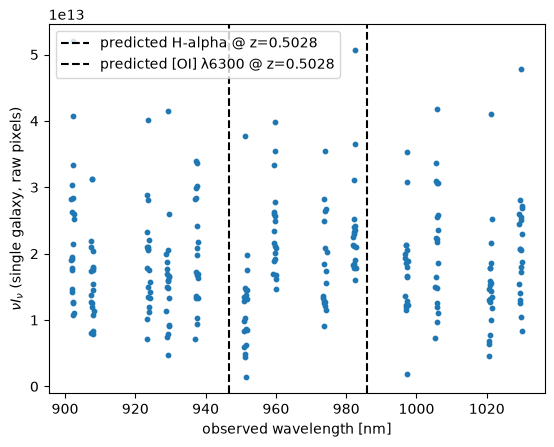

TARGETID 39628029122576483, z=0.5002, 379 pixels within 0.25 arcmin


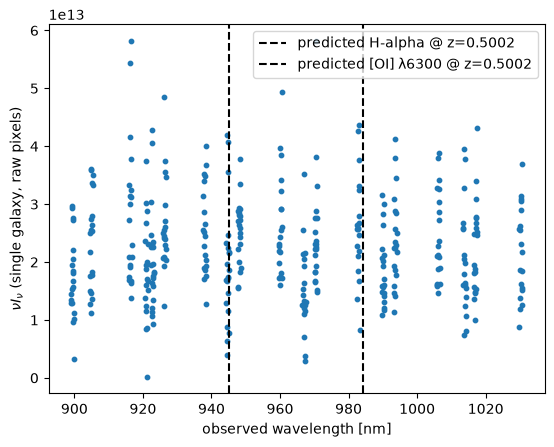

TARGETID 39628047011283646, z=0.5034, 236 pixels within 0.25 arcmin


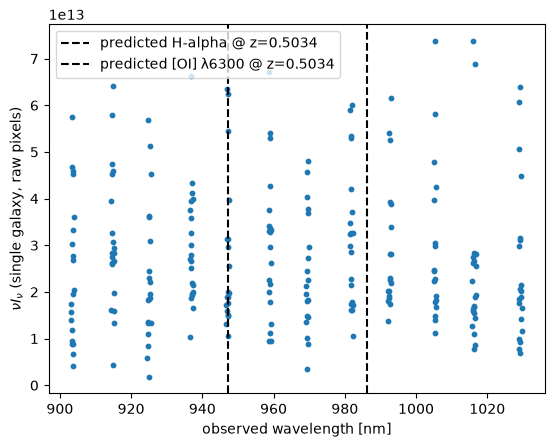

In [14]:
TEST_RADIUS_ARCMIN = 15 / 60

for GAL_SEED in range(5):
    
    test_row = tiny_sample[np.random.default_rng(GAL_SEED).integers(len(tiny_sample))]
    z_test = test_row['Z']
    
    test_query = (
        PixelQuery(web=False)
        .disc(test_row['RA'], test_row['DEC'], TEST_RADIUS_ARCMIN)
        .with_wavelengths()
        .flags(mask_known_source=False)
        .wavelength(QUERY_WL_MIN, QUERY_WL_MAX * 0.95)
    )
    test_table = test_query.execute()
    
    test_wl_obs   = test_table.column("wavelength").to_numpy()
    test_freq_obs = (const.c / (test_wl_obs * u.micrometer)).to(u.Hz).value
    test_I_obs    = test_freq_obs * (test_table.column("flux").to_numpy() - test_table.column("zodi").to_numpy())
    
    print(f"TARGETID {test_row['TARGETID']}, z={z_test:.4f}, {len(test_wl_obs)} pixels within {TEST_RADIUS_ARCMIN} arcmin")
    
    predicted_obs = WL_REST_HALPHA * (1 + z_test)
    predicted_OI  = 0.6300 * (1 + z_test)
    
    fig, ax = plt.subplots()
    ax.scatter(test_wl_obs * 1e3, test_I_obs, s=10)
    ax.axvline(predicted_obs * 1e3, color='k', ls='--', label=f'predicted H-alpha @ z={z_test:.4f}')
    ax.axvline(predicted_OI  * 1e3, color='k', ls='--', label=f'predicted [OI] λ6300 @ z={z_test:.4f}')
    ax.set_xlabel('observed wavelength [nm]')
    ax.set_ylabel(r'$\nu I_\nu$ (single galaxy, raw pixels)')
    ax.legend()
    plt.show()

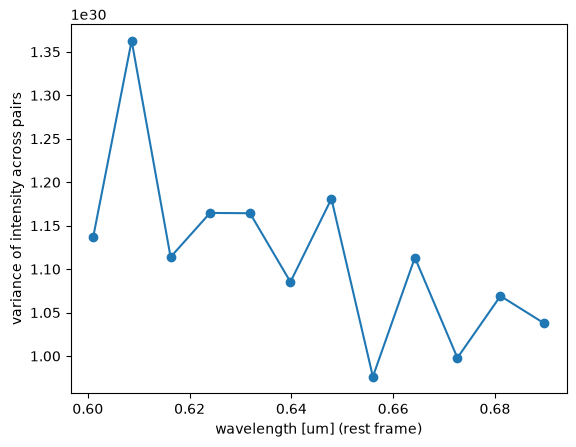

In [15]:
fig, ax = plt.subplots()
ax.plot(wl_c[:-3], np.nanmean(variance, axis=0)[:-3], marker='o')
ax.set_xlabel('wavelength [um] (rest frame)')
ax.set_ylabel('variance of intensity across pairs')
plt.show()

### Masking Gaia sources

In [10]:
def query_gaia_sources(ra_deg, dec_deg, search_radius_arcmin=3.0, mag_limit=20.0):
    """
    query IRSA's Gaia DR3 mirror (table 'gaia_dr3_source') for sources
    within `search_radius_arcmin` of (ra_deg, dec_deg).
    """
    coord = SkyCoord(ra=ra_deg * u.deg, dec=dec_deg * u.deg, frame="icrs")
 
    table = Irsa.query_region(
        coord,
        catalog="gaia_dr3_source",
        spatial="Cone",
        radius=search_radius_arcmin * u.arcmin,
        columns="source_id,ra,dec,phot_g_mean_mag,phot_bp_mean_mag,phot_rp_mean_mag",
    )

    # hard cut on G magnitude
    table = table[table["phot_g_mean_mag"] < mag_limit]
    return table
 
 
def mask_radius_arcsec(g_mag):
    """
    Convert Gaia G magnitude -> masking radius in arcsec.
 
    ASSUMPTION: this form is a placeholder model containing:
      - a floor radius roughly matching SPHEREx PSF FWHM (2-7" across
        bands; 4" used here)
      - a term that grows for brighter sources, standing in for the wings
        of the PSF + diffraction spikes/bleed
 
    SPHEREx's own mask radius is discussed in Explanatory Supplement Eq. 13
    """
    floor_radius = 4.0  # arcsec
    bright_term = 50.0 * 10 ** (-0.2 * g_mag)
 
    radius = floor_radius + bright_term
    return radius
 
 
def build_mask_table(ra_deg, dec_deg, search_radius_arcmin=3.0, mag_limit=20.0):
    """Query Gaia and attach a mask radius column. Returns an astropy Table."""
    sources = query_gaia_sources(ra_deg, dec_deg, search_radius_arcmin, mag_limit)
    sources["mask_radius_arcsec"] = mask_radius_arcsec(
        np.asarray(sources["phot_g_mean_mag"])
    )
    return sources

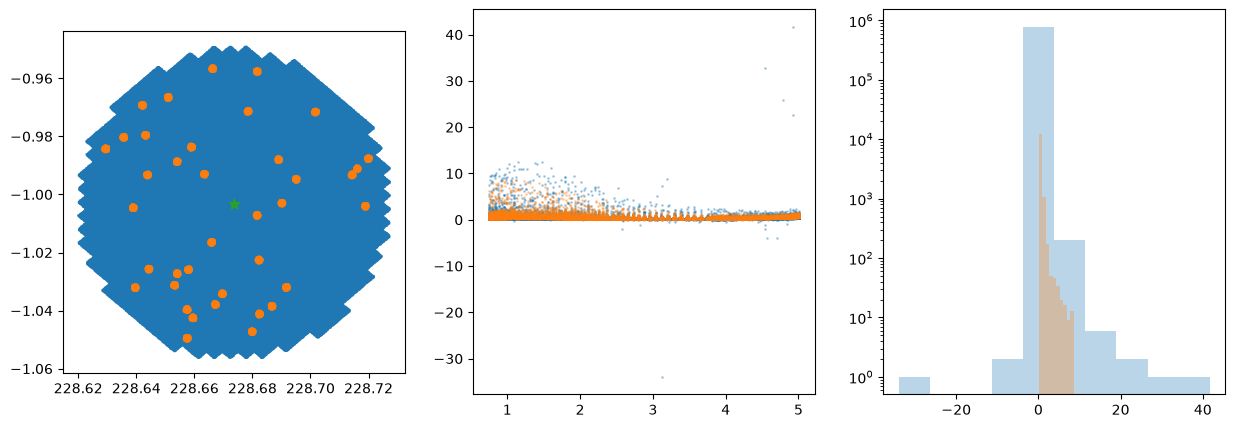

KeyboardInterrupt: 

In [17]:
rng = np.random.default_rng(112)

idx = rng.choice(len(data), size=(5,))
for i in idx:
    _ra = data[i]['RA']
    _dec = data[i]['DEC']

    _table = PixelQuery(web=False).disc(_ra, _dec, QUERY_RADIUS_ARCMIN).flags(mask_known_source=False).with_wavelengths().execute()

    _mask_table = build_mask_table(_ra, _dec)
    mask_source_coords = SkyCoord(ra=_mask_table["ra"], dec=_mask_table["dec"])

    ra, dec = healpy.pix2ang(2**22, _table.column("hphigh").to_numpy(), nest=True, lonlat=True)
    pixel_coords = SkyCoord(ra=ra, dec=dec, unit='deg')

    mask_out = np.zeros(len(ra), dtype=bool)
    for i in range(len(_mask_table)):
        mask_out |= (
            mask_source_coords[i].separation(pixel_coords).to(u.arcsec).value
            < _mask_table['mask_radius_arcsec'][i]
        )
    
    # flags = _table.column("flags").to_numpy()
    flux = _table.column("flux").to_numpy()
    wave = _table.column("wavelength").to_numpy()

    fig, axs = plt.subplots(1, 3, figsize=(15, 5))

    axs[0].scatter(ra[~mask_out], dec[~mask_out], s=1, alpha=0.3)
    axs[0].scatter(ra[mask_out], dec[mask_out], s=1, alpha=0.3)
    axs[0].axis('scaled')
    axs[0].scatter(_ra, _dec, s=64, marker='*')

    axs[1].scatter(wave[~mask_out], flux[~mask_out], s=1, alpha=0.3)
    axs[1].scatter(wave[mask_out], flux[mask_out], s=1, alpha=0.3)

    axs[2].hist(flux[~mask_out], alpha=0.3)
    axs[2].hist(flux[mask_out], alpha=0.3)
    axs[2].set_yscale('log')
    
    plt.show()

## Open questions / TODO

- Confirm the ~1.1um (observed) line suspected to be geocoronal He I is really clear of the query band now (was ~0.87-1.12um at 20 bins; should be ~0.90-1.09um at 15) -- check the variance diagnostic once rerun.
- `mask_known_source=True` removes real signal at the smallest r along with the contamination it was fixing -- consider a hybrid query (masked inner region, unmasked outer) if the innermost bins turn out to matter.
- Not yet doing anything with `WEIGHT`/`WEIGHT_COMP` from the LSS catalog -- revisit once past the prototype stage.
- Still comoving distance convention throughout (not proper), by choice for now.